In [1]:
# Initalize data 
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import h5py 

# Import data
root = "/home/lwu/work/NarrativeGenomics/region_narration/code/pipeline/ARCHS4_LW/genesets/check_if_biosamples_categories_match_with_genesets/"
filename = root + 'h.c1.c2.all.v7.5.1.symbols.gmt'

root = "/home/lwu/work/NarrativeGenomics/region_narration/code/pipeline/ARCHS4_LW/refining/data_slash_results/"
h5py_filename = root + 'archs4_gene_human_v2.1_normalized_LW20230126.h5'
with h5py.File(h5py_filename, 'r') as f:
    raw_matrix = f['data/raw_matrix'][:]
    threshold_matrix = f['data/threshold_matrix'][:]
    corrected_matrix = f['data/corrected_matrix'][:]
    qn_matrix = f['data/qn_matrix'][:]
    gene_names = f['meta/genes/all_gene_names'][:]
    raw_categories = f['meta/biosamples/all_biosample_category'][:]
    filtered_categories = f['meta/biosamples/category'][:]

raw_categories = [x.decode('UTF-8') for x in raw_categories]
filtered_categories = [x.decode('UTF-8') for x in filtered_categories]
gene_names = [x.decode('UTF-8') for x in gene_names]

# Variables 
category_dict  = {
    "Cardiovascular System" : ["Heart", "Atrium", "Cardiac Muscle Fiber", 
                               "Pericardium", "Valve", "Ventricle",
                               "HUVEC"], 
    
    "Connective Tissue" : ["Adipose", "Adipocyte", "Myofibroblast", "Osteoblast", "Stromal Cell", 
                           "MG63", "K562", "Bone Marrow", "Chondrocyte", "HT1080", "NHDF"],

    "Digestive System": ["HCT116", "HT29", "RKO", "Colon", "Colonic Muscosa", "Intestinal Epithelial Cell", 
                         "Small Intestine", "Liver", "Hepatic Stellate Cell", "Hepatocyte", "Primary Liver Cell",
                         "HEPG2", "Alpha Cell", "Beta Cell", "Pancreatic Islet", 
                         "GSE81547", "PANC1", "Gastric Epithelial Cell", "Esophagus"],
    
    "Immune System" : ["Granulocyte", "Neutrophil", "Blymphocyte", "Plasma Cell", "Plasmacytoid Dendritic Cell", 
                       "Tlymphocyte", "GSM2679484", "JURKAT", "MT4", "NALM6", "REH", "RPMI8226", "Alveolar", 
                       "Dendritic", "Kupffer", "Macrophage", "Macroglia", "JEG3", "Thymus", "Thymocyte", "Spleen"],
    
    "Integumentary System" : ["Skin", "Basal Cell", "Fibroblast", "Hair Follicle", "Keratinocyte", "Melanocyte",
                              "A431", "HACAT", "HNSCC"], 
    
    "Muscular System" : ["Skeletal Muscle", "Myoblast", "Airway Smooth Muscle", "Respiratory Smooth Muscle", 
                         "Vascular Smooth Muscle", "LHCNM2"], 
    
    "Nervous System" : ["Brain", "DAOY", "IMR32", "SKNSH", "Astrocyte", "Cerebellum", "Cerebral Cortex", 
                        "Hypothalamus", "Medula", "Midbrain", "Neuron", "Oligodendrocyte", "Pons", "Spinal Cord", 
                        "Thalamus", "Retina", "Motor Neuron", "Sensory Neuron"], 
    
    "Respiratory System" : ["Lung", "Lung Epithelial", "A549", "H1299", "IMR90", "MRC5", "NCIH460", "NHBE", 
                            "Trachea"], 
    
    "Urogenital System" : ["Breast", "Mammary Gland", "MCF7", "MCF10", "MDAMB231", "MDAMB468", "SKBR3", "T47D", 
                           "HELA", "Kidney", "Podocyte", "Renal Cortex", "293F", "FLPIN TREX 293", "HEK293", "C42", 
                           "DU145", "LNCAP", "PC3", "Ovary", "Granulosa", "Oocyte", "ES2", "SKOV3", "Testis"], 
}

In [2]:
# Data Check 
print("RAW")
print(raw_matrix.shape)
print(raw_matrix[0][0:5])
print()

print("THRESHOLD")
print(threshold_matrix.shape)
print(threshold_matrix[0][0:5])
print()

print("CORRECTED")
print(corrected_matrix.shape)
print(corrected_matrix[0][0:5])
print()

print("QN")
print(qn_matrix.shape)
print(qn_matrix[0][0:5])
print()

print("TOTAL GENES #")
print(len(gene_names))

RAW
(57447, 192601)
[0 0 0 0 0]

THRESHOLD
(57447, 87872)
[  0   4   7 108  78]

CORRECTED
(57447, 87872)
[0.         0.00118554 0.00207469 0.03200949 0.02311796]

QN
(57447, 87872)
[0.00030364 0.00495201 0.00581943 0.04173546 0.03309757]

TOTAL GENES #
57447


In [3]:
def get_gene_names(filename, geneset_name):
    gene_names = []
    with open(filename) as file:
        for line in file:
            line = line.strip().split('\t')
            if line[0] == geneset_name:
                gene_names = line[2:]
                break
    return gene_names

In [74]:
# Geneset name
# geneset_name1 = "PETRETTO_HEART_MASS_QTL_CIS_DN"
# geneset_name2 = "SHEDDEN_LUNG_CANCER_GOOD_SURVIVAL_A12"
# geneset_name3 = 'WP_LUNG_FIBROSIS'

# geneset_name1 = "HALLMARK_INFLAMMATORY_RESPONSE"
# geneset_name2 = "HALLMARK_PANCREAS_BETA_CELLS"
# geneset_name3 = 'HALLMARK_WNT_BETA_CATENIN_SIGNALING'

geneset_name1 = "HALLMARK_WNT_BETA_CATENIN_SIGNALING"
geneset_name2 = "LUI_THYROID_CANCER_CLUSTER_1"
geneset_name3 = 'DACOSTA_UV_RESPONSE_VIA_ERCC3_COMMON_UP'

# Call the function to get the gene names
gene_names1 = get_gene_names(filename, geneset_name1)
gene_names2 = get_gene_names(filename, geneset_name2)
gene_names3 = get_gene_names(filename, geneset_name3)

# Print the gene names
print(geneset_name1, len(gene_names1))
print(geneset_name2, len(gene_names2))
print(geneset_name3, len(gene_names3))

HALLMARK_WNT_BETA_CATENIN_SIGNALING 42
LUI_THYROID_CANCER_CLUSTER_1 52
DACOSTA_UV_RESPONSE_VIA_ERCC3_COMMON_UP 75


In [75]:
# Get geneset genes
def get_gene_indexes(gene_names, genes_names_all):
    gene_indexes = []
    for gene in gene_names:
        try:
            index = genes_names_all.index(gene)
            gene_indexes.append(index)
        except ValueError:
            print("Not Found: ", gene)
            gene_names.remove(gene)
    print()
    return gene_names, gene_indexes

# Call the function to get the gene indexes
gene_names1, gene_indexes1 = get_gene_indexes(gene_names1, gene_names)
gene_names2, gene_indexes2 = get_gene_indexes(gene_names2, gene_names)
gene_names3, gene_indexes3 = get_gene_indexes(gene_names3, gene_names)

# Print the gene indexes
print("Resulting Genes Found #")
print(len(gene_indexes1))
print(len(gene_indexes2))
print(len(gene_indexes3))
print()

print(geneset_name1, len(gene_names1))
print(geneset_name2, len(gene_names2))
print(geneset_name3, len(gene_names3))


Not Found:  NKX2-1

Not Found:  CNP
Not Found:  H2AC18
Not Found:  NAT1

Resulting Genes Found #
42
50
69

HALLMARK_WNT_BETA_CATENIN_SIGNALING 42
LUI_THYROID_CANCER_CLUSTER_1 51
DACOSTA_UV_RESPONSE_VIA_ERCC3_COMMON_UP 72


In [96]:
# COMMAND INPUT 
# Get extracted geneset data (in the form of a matrix)
geneset_name_plot_title = geneset_name1
gene_indexes_plot = gene_indexes1
gene_names_plot = gene_names1

In [97]:
# MAIN VARIABLE - RUN HERE
# Stores enrichment values across the different processed matrixes
enrichment_values = []
enrichment_values_system = []

expression_values = []

---
# Get Enrichment Values - Raw Matix 

In [98]:
# Functions 

def get_geneset_category_averages(extracted_geneset_matrix, category_dict, categories):
    result = {}
    
    for category, keywords in category_dict.items():
        column_indices = [i for i, c in enumerate(categories) if c in keywords]
        average_columns = np.mean(extracted_geneset_matrix[:, column_indices], axis=1)
        result[category] = average_columns.tolist()
    
    return result

def convert_to_matrix(result_dict):
    matrix = []
    for category, values in result_dict.items():
        matrix.append(values)
    
    return np.array(matrix).T

# OOE but with an additional log2 that I later realized is not needed (we already did log2 during QN processing)
# def perform_ooe(matrix):
#     row_avgs = np.mean(matrix, axis=1)  # Calculate row averages
#     normalized_matrix = matrix / row_avgs[:, np.newaxis]  # Divide each element by the row average
#     log2_matrix = np.log2(normalized_matrix)  # Take the logarithm base 2 of each element
    
#     return log2_matrix

def perform_ooe(extracted_matrix, geneset_catAvg_matrix):
    
    # Create an empty matrix to store the results
    normalized_matrix = np.empty_like(extracted_matrix, dtype=float)
    
    # Iterate over each row in extracted_matrix
    for i, row in enumerate(extracted_matrix):
        # Calculate the average of the corresponding index row in geneset_catAvg_matrix
        avg_row = geneset_catAvg_matrix[i]
        avg_row = np.array(avg_row)
        avg = np.mean(avg_row)
        
        if i == 0:
            print("First enrichment value:", avg)
            print()
        
        # Perform element-wise division and store the results in the normalized_matrix
        normalized_matrix[i] = row / avg
    
#     # Create a copy of the matrix
#     result = np.copy(normalized_matrix)
    
#     # Find indices where the matrix is non-zero
#     nonzero_indices = normalized_matrix != 0

#     # Apply log2 only to the non-zero elements
#     result[nonzero_indices] = np.log2(normalized_matrix[nonzero_indices])
    
      # ERROR: LOG2(0) CAUSES -INF, avoiding 0's causes NaN
#     log2_matrix = np.log2(result)  # Take the logarithm base 2 of each element
    
    return normalized_matrix

def perform_ooe_system(geneset_catAvg_matrix):
    geneset_catAvg_matrix = np.array(geneset_catAvg_matrix)

    row_avgs = np.mean(geneset_catAvg_matrix, axis=1)  # Calculate row averages

    geneset_systemAvg_ooe_matrix = geneset_catAvg_matrix / row_avgs[:, np.newaxis]

    return geneset_systemAvg_ooe_matrix

# (Can also get average expression values)
def get_enrichment_value(matrix):
    averages = np.mean(matrix, axis=0)  # Calculate row averages
    return averages

def get_filtered_matrix_enrichment_values(extracted_geneset_matrix, category_dict, categories, 
                                          matrixes_enrichment_values_system,
                                          matrixes_expression_values, matrixes_enrichment_values):
    
    geneset_catAvg_dict = get_geneset_category_averages(extracted_geneset_matrix, category_dict, categories)
    print("Geneset Category Averaged - Dict Form:")
    print()

    geneset_catAvg_matrix = convert_to_matrix(geneset_catAvg_dict)
    print("Dict to Matrix")
#     print(geneset_catAvg_matrix[0][0:5])
    print()
    
    # (DIFFERENT FROM TESTCASE, added Raw (aka NOT OOE) expression value storage)
    expression_values = get_enrichment_value(geneset_catAvg_matrix)
    matrixes_expression_values.append(expression_values.tolist())
    print("Data Stored - Expression Values")
    print()
    
    ooe_system_matrix = perform_ooe_system(geneset_catAvg_matrix)
    print("OOE System Matrix")
    print("-----------------")
#     print(ooe_system_matrix)
    print()

    ooe_matrix = perform_ooe(extracted_geneset_matrix, geneset_catAvg_matrix)
    print("OOE Matrix")
#     print(ooe_matrix[0][0:5])
    print()

    geneset_catAvg_ooe_dict = get_geneset_category_averages(ooe_matrix, category_dict, filtered_categories)
    print("Geneset Category Averaged OOE - Dict Form:")
    print()

    geneset_catAvg_ooe_matrix = convert_to_matrix(geneset_catAvg_ooe_dict)
    print("Dict to Matrix OOE")
#     print(geneset_catAvg_ooe_matrix[0][0:5])
    print()
    
    enrichment_system_values = get_enrichment_value(ooe_system_matrix)
    print("Enrichment System Values")
    print("------------------------")
#     print(enrichment_system_values)
    print()

    enrichment_values = get_enrichment_value(geneset_catAvg_ooe_matrix)
    print("Enrichment Values")
    print()
    
    matrixes_enrichment_values_system.append(enrichment_system_values.tolist())
    print("Data Stored - System Enrichment Values")
    print()

    matrixes_enrichment_values.append(enrichment_values.tolist())
    print("Data Stored - Enrichment Values")
    print()
    
    return matrixes_enrichment_values_system, matrixes_expression_values, matrixes_enrichment_values

extracted_geneset_matrix = raw_matrix[gene_indexes_plot, :] 
print("Extracted Geneset Matrix Shape:", extracted_geneset_matrix.shape)
# print(extracted_geneset_matrix[0][0:5])
print()
    
enrichment_values_system, expression_values, enrichment_values = get_filtered_matrix_enrichment_values(extracted_geneset_matrix,
                                                                                                       category_dict, raw_categories, 
                                                                                                       enrichment_values_system,                                                               
                                                                                                       expression_values,
                                                                                                       enrichment_values)

Extracted Geneset Matrix Shape: (42, 192601)

Geneset Category Averaged - Dict Form:

Dict to Matrix

Data Stored - Expression Values

OOE System Matrix
-----------------

First enrichment value: 1592.5027899116747

OOE Matrix

Geneset Category Averaged OOE - Dict Form:

Dict to Matrix OOE

Enrichment System Values
------------------------

Enrichment Values

Data Stored - System Enrichment Values

Data Stored - Enrichment Values



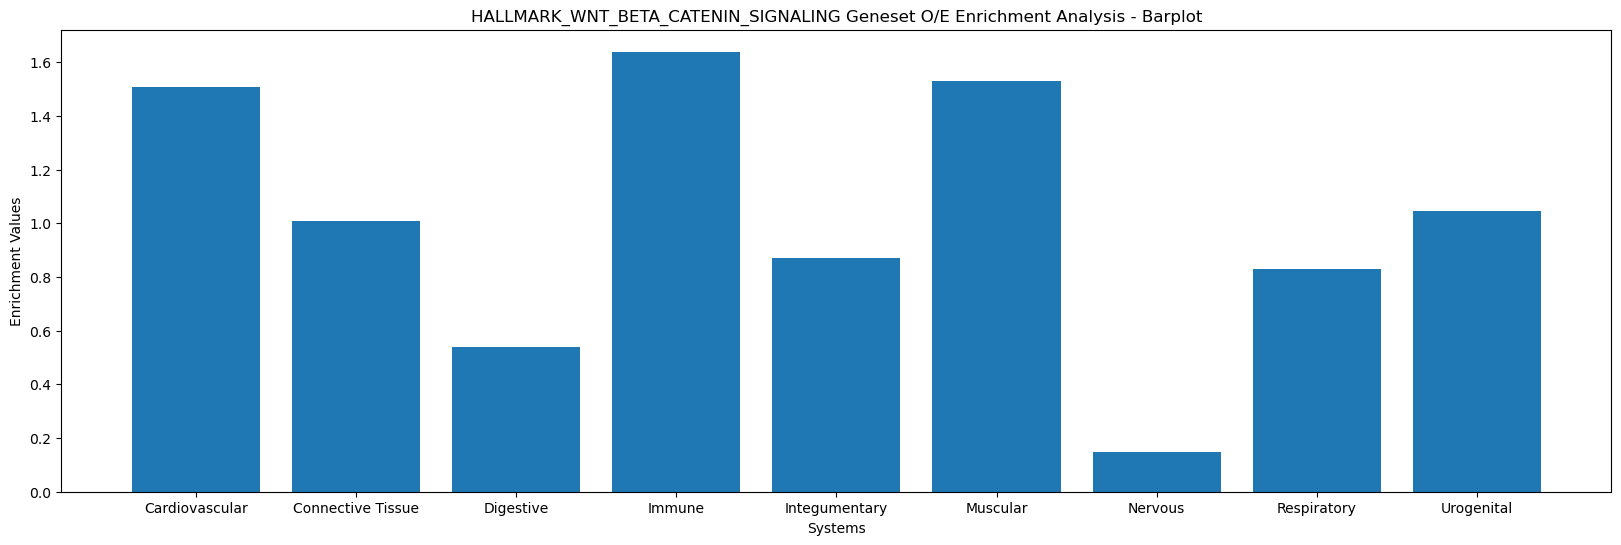

In [99]:
# PLOT RAW INDIVIDUAL MATRIX

def plot_individual_geneset_matrix(enrichment_values, category_dict):
    # Extract the category names from the dictionary keys and remove "System" from labels
    categories = [category.replace(" System", "") for category in category_dict.keys()]

    
    # Increase figure width
    plt.figure(figsize=(20, 6))

    # Plotting the barplots
    plt.bar(categories, enrichment_values)

    # Add labels and title
    plt.xlabel('Systems')
    plt.ylabel('Enrichment Values')
    plt.title(geneset_name_plot_title + ' Geneset O/E Enrichment Analysis - Barplot')

    # Display the plot
    plt.show()
    
plot_individual_geneset_matrix(enrichment_values[0], category_dict)

---
# Get System Values - Threshold Matrix 

In [100]:
# IMPORTANT: CHANGE MATRIX
extracted_geneset_matrix = threshold_matrix[gene_indexes_plot, :] 
print("Extracted Geneset Matrix Shape:", extracted_geneset_matrix.shape)
# print(extracted_geneset_matrix[0][0:5])
print()

enrichment_values_system, expression_values, enrichment_values = get_filtered_matrix_enrichment_values(extracted_geneset_matrix, 
                                                                                                       category_dict, filtered_categories, 
                                                                                                       enrichment_values_system,                                                               
                                                                                                       expression_values,
                                                                                                       enrichment_values)

Extracted Geneset Matrix Shape: (42, 87872)

Geneset Category Averaged - Dict Form:

Dict to Matrix

Data Stored - Expression Values

OOE System Matrix
-----------------

First enrichment value: 3125.671757539094

OOE Matrix

Geneset Category Averaged OOE - Dict Form:

Dict to Matrix OOE

Enrichment System Values
------------------------

Enrichment Values

Data Stored - System Enrichment Values

Data Stored - Enrichment Values



---
# Get System Values - Corrected Matrix 

In [101]:
# IMPORTANT: CHANGE MATRIX
extracted_geneset_matrix = corrected_matrix[gene_indexes_plot, :] 
print("Extracted Geneset Matrix Shape:", extracted_geneset_matrix.shape)
# print(extracted_geneset_matrix[0][0:5])
print()

enrichment_values_system, expression_values, enrichment_values = get_filtered_matrix_enrichment_values(extracted_geneset_matrix, 
                                                                                                       category_dict, filtered_categories, 
                                                                                                       enrichment_values_system,                                                               
                                                                                                       expression_values,
                                                                                                       enrichment_values)

Extracted Geneset Matrix Shape: (42, 87872)

Geneset Category Averaged - Dict Form:

Dict to Matrix

Data Stored - Expression Values

OOE System Matrix
-----------------

First enrichment value: 1.4558316237396665

OOE Matrix

Geneset Category Averaged OOE - Dict Form:

Dict to Matrix OOE

Enrichment System Values
------------------------

Enrichment Values

Data Stored - System Enrichment Values

Data Stored - Enrichment Values



---
# Get System Values - QN Matrix 

In [102]:
# IMPORTANT: CHANGE MATRIX
extracted_geneset_matrix = qn_matrix[gene_indexes_plot, :] 
# print("Extracted Geneset Matrix Shape:", extracted_geneset_matrix.shape)

enrichment_values_system, expression_values, enrichment_values = get_filtered_matrix_enrichment_values(extracted_geneset_matrix, 
                                                                                                       category_dict, filtered_categories, 
                                                                                                       enrichment_values_system,                                                               
                                                                                                       expression_values,
                                                                                                       enrichment_values)

Geneset Category Averaged - Dict Form:

Dict to Matrix

Data Stored - Expression Values

OOE System Matrix
-----------------

First enrichment value: 0.8347230520513322

OOE Matrix

Geneset Category Averaged OOE - Dict Form:

Dict to Matrix OOE

Enrichment System Values
------------------------

Enrichment Values

Data Stored - System Enrichment Values

Data Stored - Enrichment Values



---
# Plot Barplot (Each System Value/System Expected Value Method)

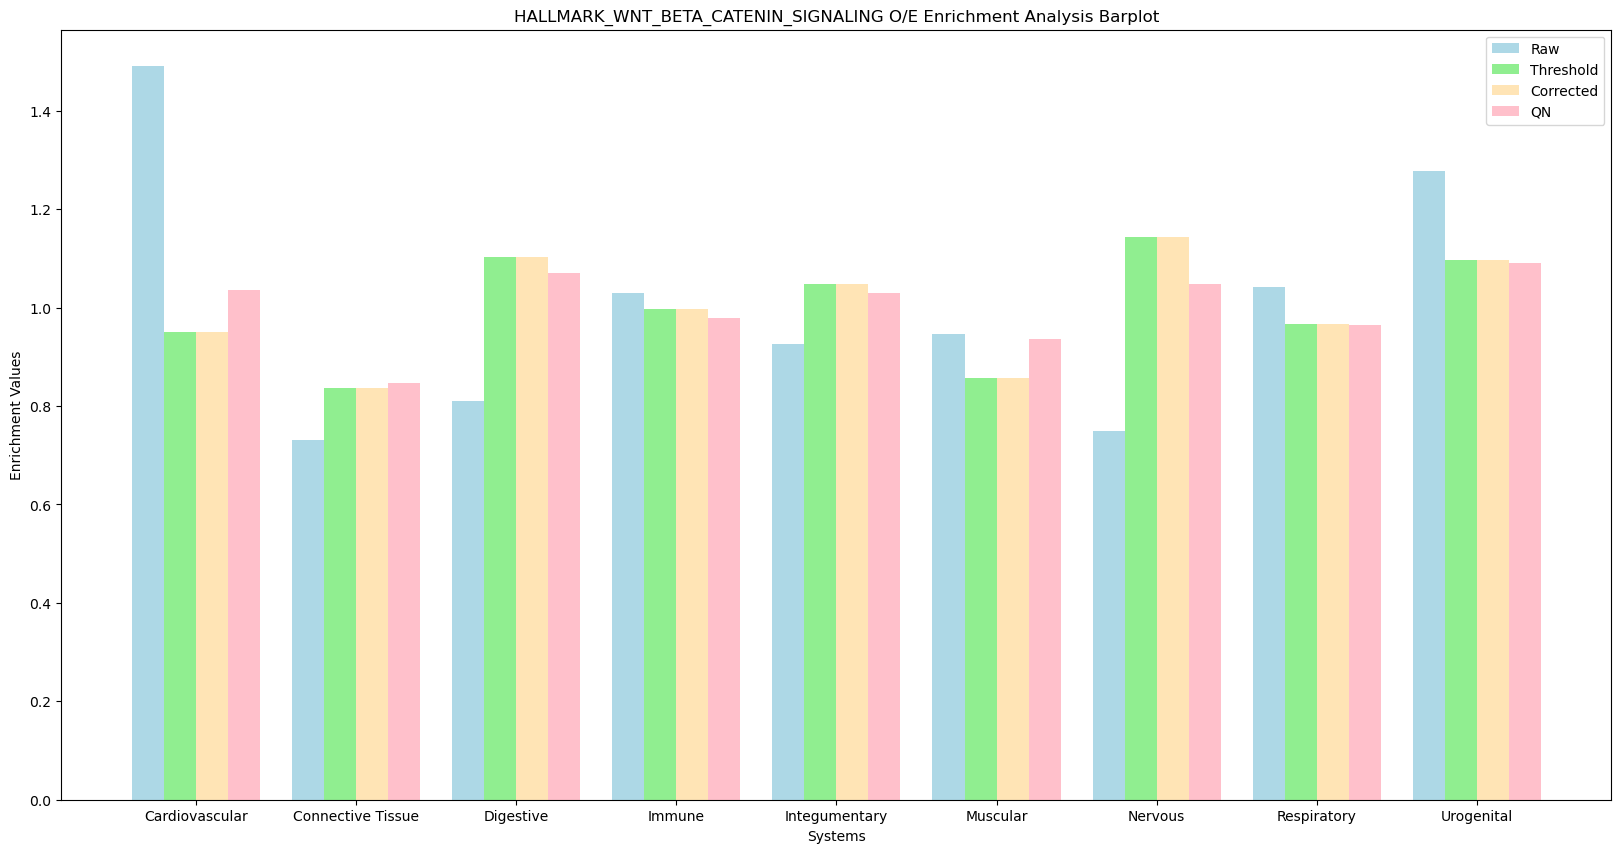

In [103]:
# Plot All Systems 

# IMPORTANT: xlabel list (TESTCASE DIFFERENCE)
xlabel_system_names = ([key.replace(" System", "") for key in category_dict.keys()])

def plot_geneset_across_matrixes(enrichment_values, category_dict, processed_matrix_names, plot_title):
    # IMPORTANT: xlabel list (TESTCASE DIFFERENCE)
    xlabel_system_names = ([key.replace(" System", "") for key in category_dict.keys()])

    # Set the width of each bar
    bar_width = 0.2

    # Calculate the x-axis positions for each bar
    x_positions = np.arange(len(xlabel_system_names))
    
    # Increase figure width
    plt.figure(figsize=(20, 10))

    # Define the colors for each matrix
    colors = ["lightblue", "lightgreen", "moccasin", "pink"]

    # Plotting the barplots for each row in enrichment_values
    for i in range(enrichment_values.shape[0]):
        center_offset = (enrichment_values.shape[0] - 1) * bar_width / 2  # Offset to center the bars
        plt.bar(x_positions + (i * bar_width) - center_offset, enrichment_values[i], width=bar_width, label=processed_matrix_names[i], color=colors[i])

    # Add labels and title
    plt.xlabel('Systems')
    plt.ylabel('Enrichment Values')
    plt.title(plot_title)
    plt.xticks(x_positions, xlabel_system_names)
    plt.legend(loc='upper right')

    # Display the plot
    plt.show()

processed_matrix_names = ["Raw", "Threshold", "Corrected", "QN"]
plot_title = geneset_name_plot_title + ' O/E Enrichment Analysis Barplot'

# (TESTCASE DIFFERENCE), added np.array onto matrixes_enrichment_values
plot_geneset_across_matrixes(np.array(enrichment_values_system), category_dict, processed_matrix_names, 
                            plot_title)


---
# Plot Barplot (Each Gene Read-Count/System Expected Value Method)

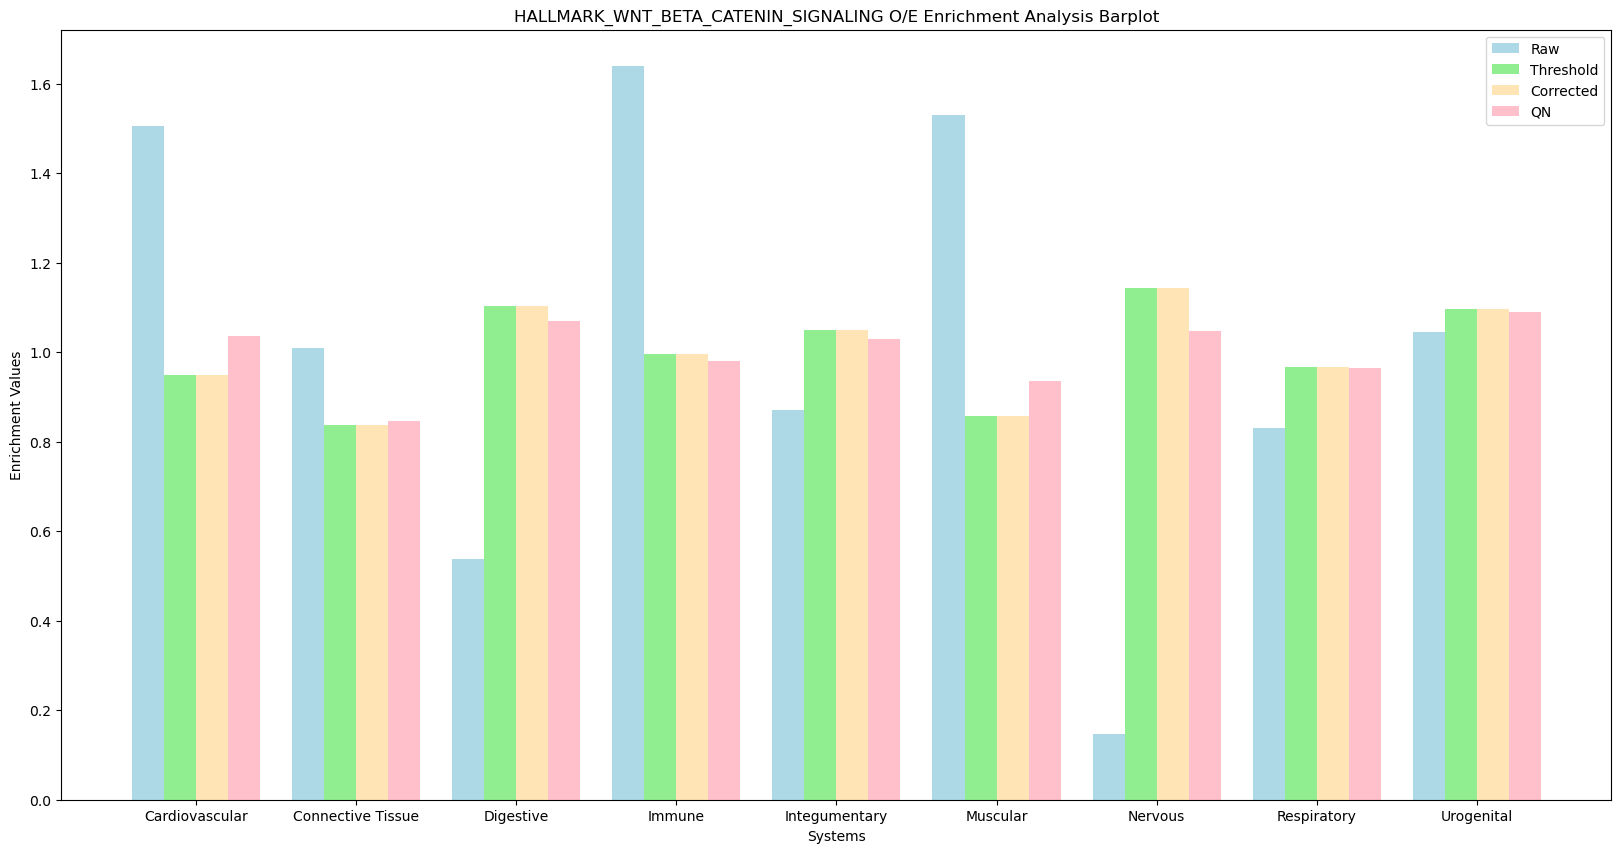

In [104]:
# Plot All Systems 

def plot_geneset_across_matrixes(enrichment_values, category_dict, processed_matrix_names, plot_title):
    # IMPORTANT: xlabel list (TESTCASE DIFFERENCE)
    xlabel_system_names = ([key.replace(" System", "") for key in category_dict.keys()])

    # Set the width of each bar
    bar_width = 0.2

    # Calculate the x-axis positions for each bar
    x_positions = np.arange(len(xlabel_system_names))
    
    # Increase figure width
    plt.figure(figsize=(20, 10))

    # Define the colors for each matrix
    colors = ["lightblue", "lightgreen", "moccasin", "pink"]

    # Plotting the barplots for each row in enrichment_values
    for i in range(enrichment_values.shape[0]):
        center_offset = (enrichment_values.shape[0] - 1) * bar_width / 2  # Offset to center the bars
        plt.bar(x_positions + (i * bar_width) - center_offset, enrichment_values[i], width=bar_width, label=processed_matrix_names[i], color=colors[i])

    # Add labels and title
    plt.xlabel('Systems')
    plt.ylabel('Enrichment Values')
    plt.title(plot_title)
    plt.xticks(x_positions, xlabel_system_names)
    plt.legend(loc='upper right')

    # Display the plot
    plt.show()

processed_matrix_names = ["Raw", "Threshold", "Corrected", "QN"]
plot_title = geneset_name_plot_title + ' O/E Enrichment Analysis Barplot'

# (TESTCASE DIFFERENCE), added np.array onto matrixes_enrichment_values
plot_geneset_across_matrixes(np.array(enrichment_values), category_dict, processed_matrix_names, 
                            plot_title)


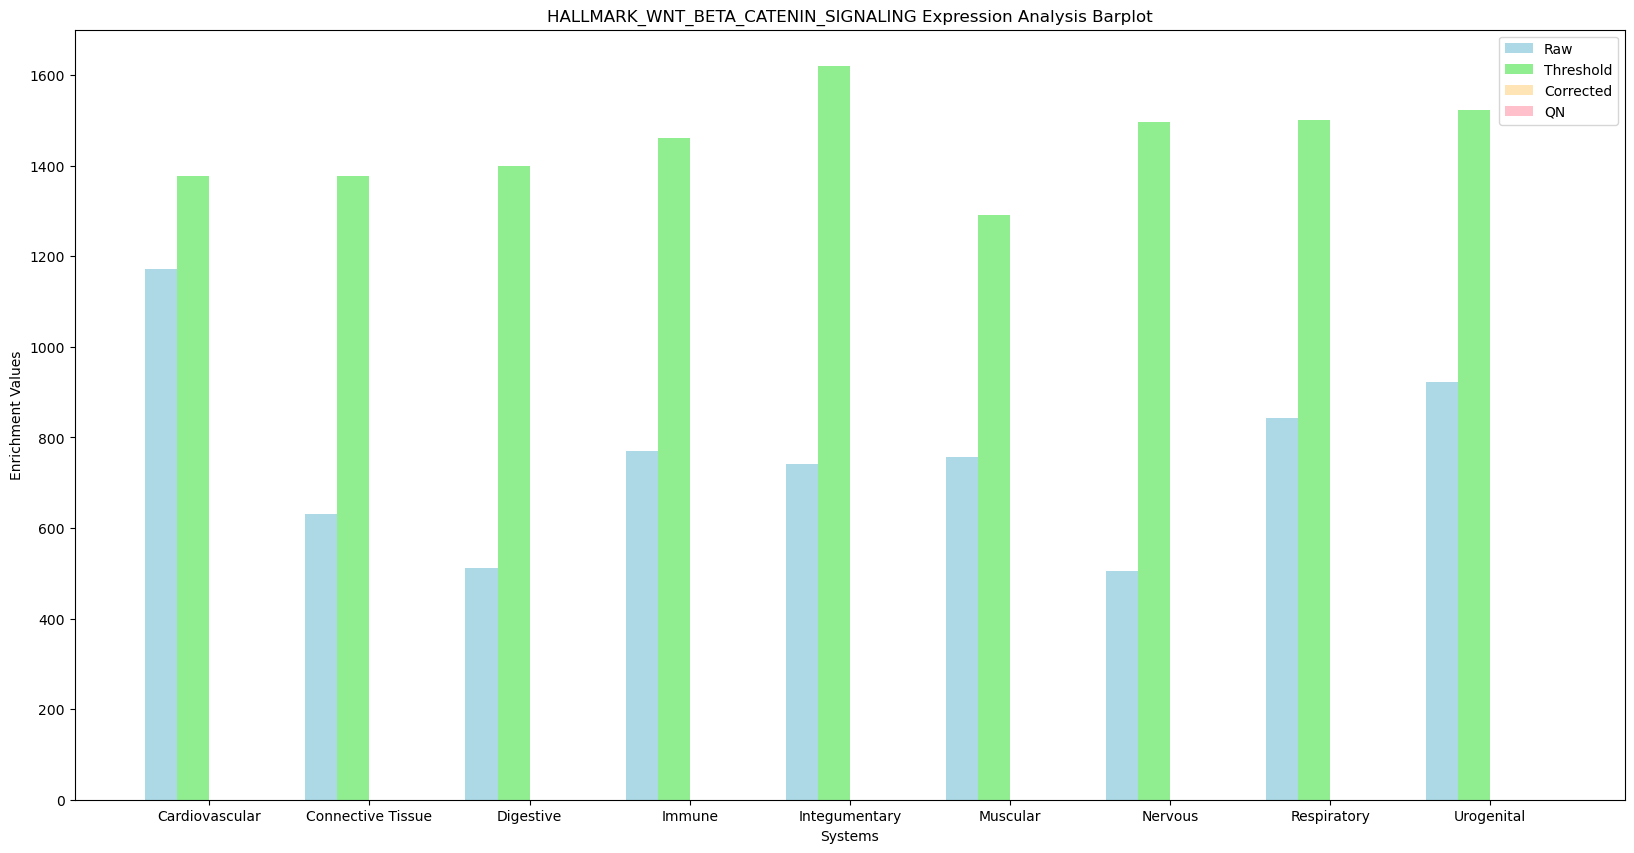

In [105]:
# (TESTCASE DIFFERENCE), expression (Raw, Not OOE) barplot 
plot_title = geneset_name_plot_title + ' Expression Analysis Barplot'
plot_geneset_across_matrixes(np.array(expression_values), category_dict, processed_matrix_names, 
                             plot_title)
